# Разведочный анализ данных (EDA) датасета [MMoRWaD](https://zenodo.org/records/22226868)

## Цель
Формирование аналитической основы для обоснованного выбора стратегии обогащения датасета MMoRWaD с учётом особенностей его структуры, состава и качества данных для задачи детекции объектов.
## Планируемая стуктура
1. Описание датасета, его назначения и структуры.
2. Анализ состава и количества данных.
3. Распределение материалов и дополнительных признаков.
4. Анализ изображений и детекционных аннотаций.
5. Исследование разделения данных.
6. Выявленные ограничения и выводы для дальнейшего обогащения.


## Задачи
1. Выяснить, как организован оригинальный MMoRWaD
2. Понять, какие файлы в нём хранятся и как связаны между собой
3. Узнать, сколько в нём изображений, предметов и классов
4. Посмотреть распределение классов
5. Выяснить, какие дополнительные характеристики записаны для каждого изображения
6. определить, как устроена разметка для детекции (bounding boxes)
7. Исследовать распределение классов между обучающей, валидационной и тестовой выборками.

## Описание датасета

MMoRWaD (Multi-Modal Recyclable Waste Management Dataset) — мультимодальный набор данных, предназначенный для исследования методов автоматического распознавания и анализа перерабатываемых отходов. В рамках данной работы рассматриваются RGB-изображения предметов и соответствующие аннотации для задачи детекции объектов.

### Загрузим наш датасет

In [1]:
import requests
import pandas as pd

RECORD_ID = 22226868
API_URL = f"https://zenodo.org/api/records/{RECORD_ID}"

response = requests.get(API_URL, timeout=30)
response.raise_for_status()

record = response.json()

print("Название датасета:", record["metadata"]["title"])
print("Количество файлов:", len(record["files"]))


files_info = []

for file in record["files"]:
    files_info.append({
        "Название файла": file["key"],
        "Размер (МБ)": round(file["size"] / (1024 ** 2), 2),
        "Формат": file["key"].split(".")[-1]
    })

df_files = pd.DataFrame(files_info)

display(df_files)

Название датасета: MMoRWaD - The Multi Modal Recyclable Waste Management Dataset
Количество файлов: 16


,Название файла,Размер (МБ),Формат
0,split_properties.md,0.00,md
1,coco_annotations.json,8.64,json
2,baseline.zip,2.11,zip
3,depth_img.zip,839.67,zip
4,color_video.zip,1697.45,zip
5,depth_video.zip,3853.70,zip
6,item_counts.jsonl,0.05,jsonl
7,dataset.csv,0.28,csv
8,audio.zip,303.54,zip
9,color_img.zip,1520.06,zip


В ходе первичного изучения установлено, что датасет представлен 16 файлами различных форматов (.csv, .json, .jsonl, .zip, .md, .py). Набор включает цветные изображения, изображения глубины, видео, аудиозаписи, метаданные и аннотации объектов.

Судя по описанию датасета от самих авторов:
- `color_img.zip` - RGB фотографии в PNG формате
- `depth_img.zip` - информация о расстояних до поверхностей, изображения глубины
- `color_video.zip`, `depth_video.zip` - цветные видеозаписи преметов и их гулбины
- `audio.zip` - звук падения предмета
- `dataset.csv` - таблица классификационных характеристик
- `coco_annotations.json` - разметка изображений
- `item_counts.jsonl` - авторы указывают, что в нем содержится название предмета и количество его съемок (на один предмет может быть несколько снимков в разных состояних)

- `object_splits.csv` - Разбиение 721 физического предмета
- `sample_splits.csv`- Разбиение 3 300 отдельных образцов
- `split_properties.csv` - 	Сводные количественные характеристики разбиения
- `split_properties.md` - 	Те же характеристики в отчёте, включая распределение по материалам
- `make_splits.py` - Python-скрипт для воспроизведения официального разбиения.
- и другие файлы, в которых содержатся скрипты и отчеты

Это основные файлы в датасете. Для наших целей нам необходимы `color_img.zip`, `dataset.csv`, `coco_annotations.json`, `item_counts.jsonl` а также уже подготовленное авторами разбиение на выборки (по описанию авторов, они старались не допустить попадания одного предмета в разные выборки)

## Анализ `dataset.csv`

In [2]:
from pathlib import Path

DATA_DIR = Path("/content/mmorwad_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

csv_file = next(
    file for file in record["files"]
    if file["key"] == "dataset.csv"
)

csv_path = DATA_DIR / "dataset.csv"

if not csv_path.exists():
    response = requests.get(
        csv_file["links"]["self"],
        timeout=60
    )
    response.raise_for_status()

    csv_path.write_bytes(response.content)
    print("Файл скачан:", csv_path)
else:
    print("Файл уже существует:", csv_path)

df = pd.read_csv(csv_path)

print("Размерность таблицы:", df.shape)
print("\nОбщая информация о таблице:")
df.info()
df.head(10)

Файл скачан: /content/mmorwad_data/dataset.csv
Размерность таблицы: (3300, 8)

Общая информация о таблице:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3300 entries, 0 to 3299
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ID            3300 non-null   int64 
 1   Item          3300 non-null   object
 2   Material      3300 non-null   object
 3   Hue           3300 non-null   object
 4   Top/Cap       3300 non-null   object
 5   Label         3300 non-null   object
 6   Contaminates  3300 non-null   object
 7   Deformation   3300 non-null   object
dtypes: int64(1), object(7)
memory usage: 206.4+ KB


,ID,Item,Material,Hue,Top/Cap,Label,Contaminates,Deformation
0,1,zagori water bottle 0.5l,Polyethylene Terephthalate (PET),Clear,Yes,Yes,No-N/a,No-N/a
1,2,zagori water bottle 0.5l,Polyethylene Terephthalate (PET),Clear,No-N/a,Yes,No-N/a,No-N/a
2,3,zagori water bottle 0.5l,Polyethylene Terephthalate (PET),Clear,No-N/a,No-N/a,No-N/a,No-N/a
3,4,zagori water bottle 0.5l,Polyethylene Terephthalate (PET),Clear,Yes,No-N/a,No-N/a,No-N/a
4,5,zagori water bottle 0.5l,Polyethylene Terephthalate (PET),Clear,Yes,Yes,Yes,No-N/a
5,6,zagori water bottle 0.5l,Polyethylene Terephthalate (PET),Clear,Yes,No-N/a,Yes,No-N/a
6,7,zagori water bottle 0.5l,Polyethylene Terephthalate (PET),Clear,Yes,No-N/a,No-N/a,Yes
7,8,zagori water bottle 0.5l,Polyethylene Terephthalate (PET),Clear,No-N/a,No-N/a,No-N/a,Yes
8,9,zagori water bottle 0.5l,Polyethylene Terephthalate (PET),Clear,Yes,No-N/a,Yes,Yes
9,10,zagori water bottle 0.5l,Polyethylene Terephthalate (PET),Clear,Yes,Yes,Yes,Yes


### Проверим пропуски, дубликаты, уникальные значения

In [3]:
summary = pd.DataFrame({
    "Тип данных": df.dtypes,
    "Непустых значений": df.notna().sum(),
    "Пропусков": df.isna().sum(),
    "Пропусков (%)": (df.isna().mean() * 100).round(2),
    "Уникальных значений": df.nunique(dropna=True)
})
print("Количество полных дубликатов:", df.duplicated().sum())
summary

Количество полных дубликатов: 0


,Тип данных,Непустых значений,Пропусков,Пропусков (%),Уникальных значений
ID,int64,3300,0,0.0,3300
Item,object,3300,0,0.0,721
Material,object,3300,0,0.0,18
Hue,object,3300,0,0.0,16
Top/Cap,object,3300,0,0.0,2
Label,object,3300,0,0.0,2
Contaminates,object,3300,0,0.0,2
Deformation,object,3300,0,0.0,2


Как мы можем видеть, фактические данные сходятся с описанием авторов. Количество полных дубликатов и пропусков равно 0. Различных материалов 18. Количество уникальных ID 3300, значит у каждой записи свой идентификатор, и поскольку 721 - число уникальных предметов - меньше, чем 3300, это подтверждает, что сделаны несколько записей одного предмета. Столбцы, кроме ID и Item, можно считать категориальными по смыслу и малому количеству уникальных значений

### Исследуем категориальные признаки

In [4]:
features = [
    "Material",
    "Hue",
    "Top/Cap",
    "Label",
    "Contaminates",
    "Deformation"
]

for col in features:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index().to_string())


Material:
Material
Aluminium (ALU)                                  167
Brown Glass (GL)                                  36
Cardboard (PAP)                                   61
Clear Glass (GL)                                 109
Green Glass (GL)                                  10
High Density Polyethylene (HDPE)                 488
Low Density Polyethylene (LDPE)                   35
Other Plastic (Other)                            103
Paper (PAP)                                       38
Paper/Cardboard + Plastic (C/PAP)                 76
Paper/Cardboard + Plastic + Aluminum (C/PAP)      96
Paperboard (PAP)                                 375
Plastic + Aluminium (C/PE)                        32
Polyethylene Terephthalate (PET)                1146
Polypropylene (PP)                               432
Polystyrene (PS)                                  14
Polyvinyl Chloride (PVC)                           5
Steel (FE)                                        77

Hue:
Hue
Black           

Наиболее частые материалы в датасете — PET, HDPE и PP. Они создают значительный дисбаланс относительно других видов материалов. Основываясь на собственном опыте, можно предположить, что пластиковая упаковка часто встречается среди бытовых отходов, поэтому такое распределение потенциально может отражать реальные условия применения модели. Однако это предположение требует дополнительного подтверждения, а сам дисбаланс может негативно сказаться на распознавании редких материалов. В рамках дальнейшего исследования планируется сохранить исходное распределение классов и оценить, как различные способы обогащения данных влияют на качество их распознавания.

Цвета представлены различные. Наиболее частые - прозрачный и other

По бинарным категориям тоже наблюдается дисбаланс. Но значение No-N/a не всегда означает отсутствие, так как к некоторым материалам неприминима этикетка или крышка, например к обычному листу бумаги

### Переименуем названия материалов для удобства отображения


In [5]:
material_names = {
    "Polyethylene Terephthalate (PET)": "PET",
    "High Density Polyethylene (HDPE)": "HDPE",
    "Low Density Polyethylene (LDPE)": "LDPE",
    "Polypropylene (PP)": "PP",
    "Polystyrene (PS)": "PS",
    "Polyvinyl Chloride (PVC)": "PVC",
    "Other Plastic (Other)": "Other",
    "Aluminium (ALU)": "ALU",
    "Steel (FE)": "FE",
    "Clear Glass (GL)": "Clear Glass (GL)",
    "Green Glass (GL)": "Green Glass (GL)",
    "Brown Glass (GL)": "Brown Glass (GL)",
    "Paper (PAP)": "Paper (PAP)",
    "Paperboard (PAP)": "Paperboard (PAP)",
    "Cardboard (PAP)": "Cardboard (PAP)",
    "Paper/Cardboard + Plastic (C/PAP)": "Paper + Plastic (C/PAP)",
    "Paper/Cardboard + Plastic + Aluminum (C/PAP)": "Paper + Plastic + Al (C/PAP)",
    "Plastic + Aluminium (C/PE)": "Plastic + Al (C/PE)"
}

assert set(df["Material"].unique()) == set(material_names)

df_eda = df.copy()
df_eda["Material"] = df_eda["Material"].map(material_names)

df_eda["Material"].value_counts()

,count
Material,
PET,1146
HDPE,488
PP,432
Paperboard (PAP),375
ALU,167
Clear Glass (GL),109
Other,103
Paper + Plastic + Al (C/PAP),96
FE,77


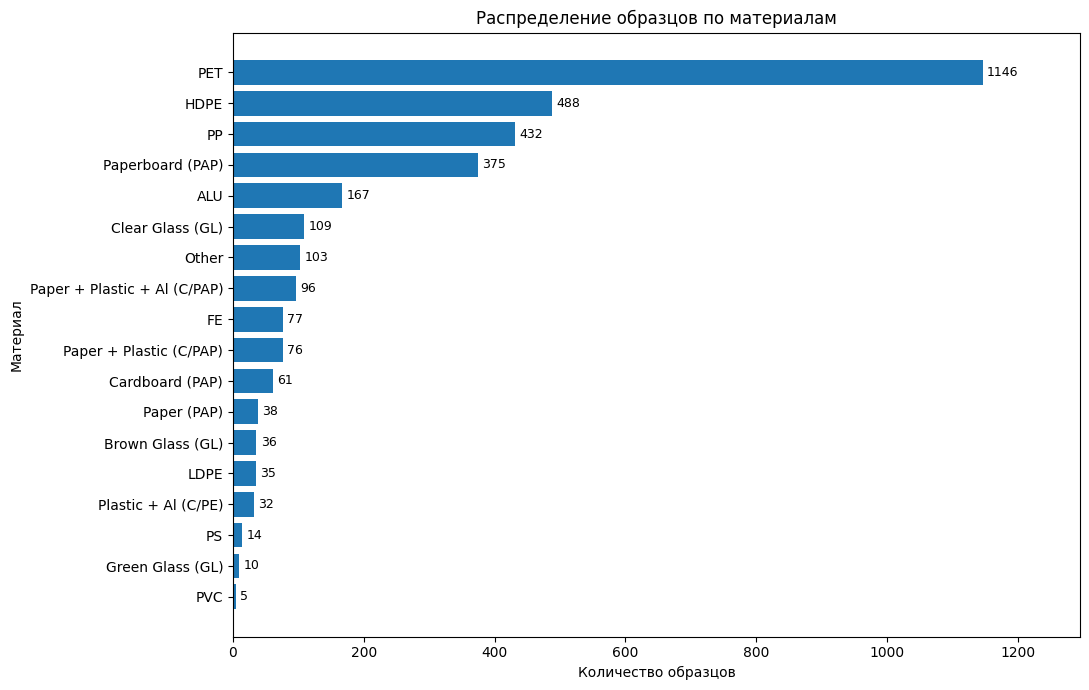

In [6]:
import matplotlib.pyplot as plt

material_counts = df_eda["Material"].value_counts().sort_values()

plt.figure(figsize=(11, 7))

bars = plt.barh(
    material_counts.index,
    material_counts.values
)

plt.bar_label(bars, padding=3, fontsize=9)

plt.title("Распределение образцов по материалам")
plt.xlabel("Количество образцов")
plt.ylabel("Материал")

plt.xlim(0, material_counts.max() * 1.13)
plt.tight_layout()
plt.show()

### Объединим материалы в 5 логических больших групп

In [7]:
material_groups = {
    "Пластик": [
        "PET",
        "HDPE",
        "LDPE",
        "PP",
        "PS",
        "PVC",
        "Other"
    ],
    "Бумага и картон": [
        "Paper (PAP)",
        "Paperboard (PAP)",
        "Cardboard (PAP)"
    ],
    "Металл": [
        "ALU",
        "FE"
    ],
    "Стекло": [
        "Clear Glass (GL)",
        "Green Glass (GL)",
        "Brown Glass (GL)"
    ],
    "Композиты": [
        "Paper + Plastic (C/PAP)",
        "Paper + Plastic + Al (C/PAP)",
        "Plastic + Al (C/PE)"
    ]
}

material_to_group = {
    material: group
    for group, materials in material_groups.items()
    for material in materials
}

df_grouped = df_eda.copy()
df_grouped["Material_group"] = df_grouped["Material"].map(material_to_group)

assert df_grouped["Material_group"].notna().all()

group_counts = df_grouped["Material_group"].value_counts()

group_counts

,count
Material_group,
Пластик,2223
Бумага и картон,474
Металл,244
Композиты,204
Стекло,155


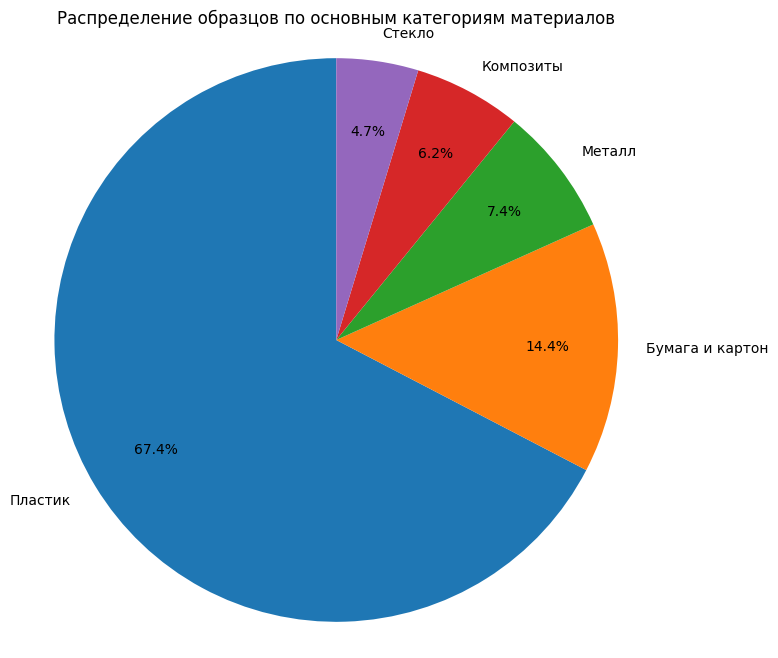

In [8]:
plt.figure(figsize=(8, 8))

plt.pie(
    group_counts.values,
    labels=group_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75
)

plt.title("Распределение образцов по основным категориям материалов")
plt.axis("equal")
plt.show()

Также посмотрим для цветов и бинарных признаков

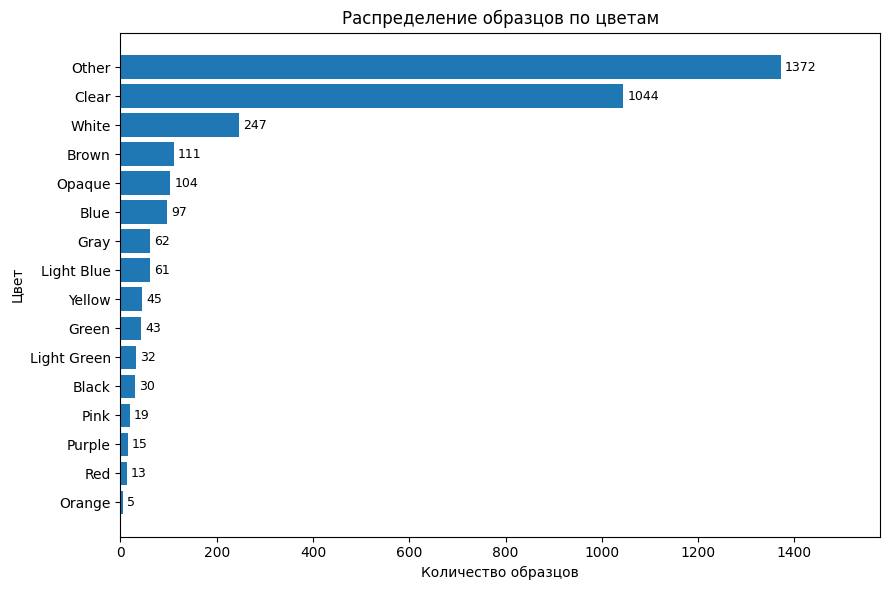

In [9]:
hue_counts = df["Hue"].value_counts().sort_values()

plt.figure(figsize=(9, 6))

bars = plt.barh(hue_counts.index, hue_counts.values)
plt.bar_label(bars, padding=3, fontsize=9)

plt.title("Распределение образцов по цветам")
plt.xlabel("Количество образцов")
plt.ylabel("Цвет")
plt.xlim(0, hue_counts.max() * 1.15)

plt.tight_layout()
plt.show()

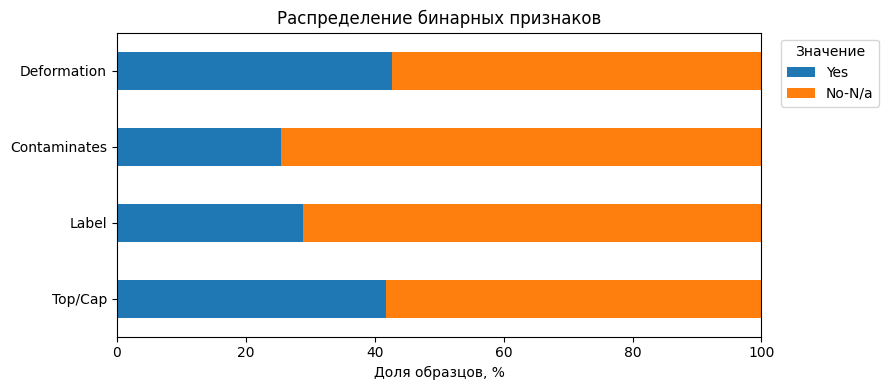

In [10]:
binary_cols = ["Top/Cap", "Label", "Contaminates", "Deformation"]

binary_data = pd.DataFrame({
    col: df[col].value_counts(normalize=True) * 100
    for col in binary_cols
}).T

binary_data = binary_data[["Yes", "No-N/a"]]

ax = binary_data.plot(
    kind="barh",
    stacked=True,
    figsize=(9, 4)
)

ax.set_title("Распределение бинарных признаков")
ax.set_xlabel("Доля образцов, %")
ax.set_ylabel("")
ax.legend(title="Значение", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### Посмотрим сколько в среднем фото на один предмет

Количество уникальных предметов: 721
Минимум образцов на предмет: 1
Максимум образцов на предмет: 19
Среднее количество: 4.58
Медиана: 3.0


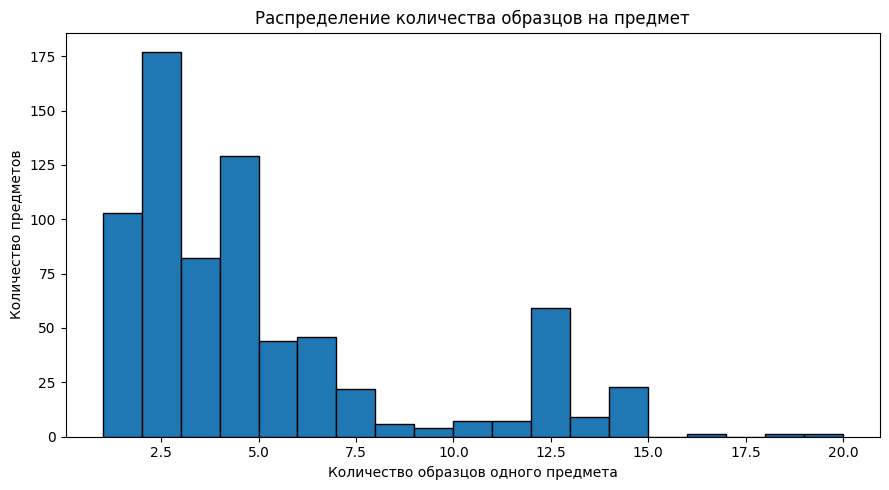

In [11]:
item_counts = df.groupby("Item")["ID"].nunique()

print("Количество уникальных предметов:", item_counts.size)
print("Минимум образцов на предмет:", item_counts.min())
print("Максимум образцов на предмет:", item_counts.max())
print("Среднее количество:", round(item_counts.mean(), 2))
print("Медиана:", item_counts.median())

plt.figure(figsize=(9, 5))

plt.hist(
    item_counts,
    bins=range(1, int(item_counts.max()) + 2),
    edgecolor="black"
)

plt.title("Распределение количества образцов на предмет")
plt.xlabel("Количество образцов одного предмета")
plt.ylabel("Количество предметов")

plt.tight_layout()
plt.show()

Можем сделать вывод, что в среднем было сделано 2-5 фото

## Анализ изображений и COCO-аннотаций

### Загрузим необходимые файлы

In [12]:
import json
import zipfile
import re
from PIL import Image
import matplotlib.patches as patches
from pathlib import PurePosixPath

def download_from_zenodo(record, key, data_dir=DATA_DIR, timeout=120):
    file_info = next(file for file in record["files"] if file["key"] == key)
    file_path = data_dir / key

    if not file_path.exists():
        response = requests.get(file_info["links"]["self"], timeout=timeout)
        response.raise_for_status()
        file_path.write_bytes(response.content)
        print(f"Файл скачан: {file_path}")
    else:
        print(f"Файл уже существует: {file_path}")

    return file_path

ann_path = download_from_zenodo(record, "coco_annotations.json")
img_zip_path = download_from_zenodo(record, "color_img.zip")

Файл скачан: /content/mmorwad_data/coco_annotations.json
Файл скачан: /content/mmorwad_data/color_img.zip


In [13]:
with open(ann_path, "r",encoding="utf-8") as f:
    coco = json.load(f)
print("Ключи словаря COCO", coco.keys())
print("Количество изображений", len(coco["images"]))
print("Количество аннотаций", len(coco["annotations"]))
print("Количество категорий:", len(coco["categories"]))

Ключи словаря COCO dict_keys(['images', 'annotations', 'categories'])
Количество изображений 3300
Количество аннотаций 3300
Количество категорий: 3300


In [14]:
images_df = pd.DataFrame(coco["images"])
annotations_df = pd.DataFrame(coco["annotations"])
categories_df = pd.DataFrame(coco["categories"])

print("Images:")
print(images_df.head())

print("Annotations:")
print(annotations_df.head())

print("Categories:")
print(categories_df.head())
images_df.groupby(["width", "height"]).size()

Images:
   id               file_name  height  width
0   1  1ic_M01H00T1L1C0D0.png     480    848
1   2  2ic_M01H00T0L1C0D0.png     480    848
2   3  3ic_M01H00T0L0C0D0.png     480    848
3   4  4ic_M01H00T1L0C0D0.png     480    848
4   5  5ic_M01H00T1L1C1D0.png     480    848
Annotations:
   id  image_id                                       segmentation  \
0   1         1  [[431, 322, 441, 325, 443, 328, 449, 327, 457,...   
1   2         2  [[356, 233, 361, 234, 364, 234, 367, 235, 372,...   
2   3         3  [[576, 260, 568, 263, 479, 268, 470, 268, 459,...   
3   4         4  [[344, 165, 370, 188, 411, 221, 436, 242, 444,...   
4   5         5  [[392, 176, 402, 176, 409, 177, 413, 175, 424,...   

                   bbox     area  iscrowd  
0  [419, 322, 192, 108]  10229.0        0  
1   [345, 233, 195, 96]   9622.0        0  
2   [416, 259, 201, 71]  10974.0        0  
3  [342, 122, 178, 152]  10851.5        0  
4   [391, 154, 194, 66]  10152.0        0  
Categories:
   id  image

,,0
width,height,
848,480,3300


Разрешение всех изображений одинаковое.

В файле, кроме разметки бокса, содержится еще и полная информация по самому предмету.

Проверим, полностью ли соответсвует categories с daеaset.csv?

In [15]:
merged = df[["ID", "Material"]].merge(
    categories_df[["image_id", "material"]],
    left_on="ID",
    right_on="image_id",
    how="inner"
)

print("Совпадающих записей:", len(merged))
print("Несовпадений материалов:",(merged["Material"] != merged["material"]).sum())

Совпадающих записей: 3300
Несовпадений материалов: 0


Несовпадающих материалов 0, получается, что информация по материалу предмета согласована между файлами

### Проверим сколько обычно аннотаций на одно фото

In [16]:
ann_per_image = annotations_df.groupby("image_id").size()

print("Минимум аннотаций на изображение:", ann_per_image.min())
print("Максимум аннотаций на изображение:", ann_per_image.max())
print("Среднее количество аннотаций:", round(ann_per_image.mean(), 2))
print("Медиана:", ann_per_image.median())

ann_per_image.value_counts().sort_index()

Минимум аннотаций на изображение: 1
Максимум аннотаций на изображение: 1
Среднее количество аннотаций: 1.0
Медиана: 1.0


,count
1,3300


Получается на каждом фото только один предмет для описания

Также можем заметить что COCO немного не стандартный. В нем нет поля category_id.
В стандартной аннотации coco обычно содержится примерно такое:
``` python
categories = [
    {"id": 1, "name": "PET"},
    {"id": 2, "name": "HDPE"}
]

annotations = [
    {
        "image_id": 1,
        "category_id": 1,
        "bbox": [419, 322, 192, 108]
    }
]
```
Для дальнейшей работы можно практически не использовать dataset.csv, а использовать преобразованный coco_annotations.json, поскольку в нем есть вся необходимая информация по материалам и описанию предмета

### Визуализация рамок

Загрузка изображения

In [17]:
from io import BytesIO

archive = zipfile.ZipFile(img_zip_path, "r")

image_paths = {
    PurePosixPath(name).name: name
    for name in archive.namelist()
    if name.lower().endswith((".png", ".jpg", ".jpeg"))
}

print("Изображений в архиве:", len(image_paths))

Изображений в архиве: 3300


In [18]:
def load_image(file_name):
    archive_path = image_paths[file_name]

    with archive.open(archive_path) as file:
        image = Image.open(BytesIO(file.read())).convert("RGB")

    return image

Отрисовка рамки

In [19]:
def show_bbox(image_id):
    image_info = images_df.loc[images_df["id"] == image_id].iloc[0]
    image = load_image(image_info["file_name"])
    image_annotations = annotations_df[annotations_df["image_id"] == image_id]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.imshow(image)

    for _, ann in image_annotations.iterrows():
        x, y, w, h = ann["bbox"]

        rect = patches.Rectangle(
            (x, y), w, h,
            fill=False,
            edgecolor="red",
            linewidth=1
        )
        ax.add_patch(rect)

    ax.set_title(f"Image ID: {image_id}")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

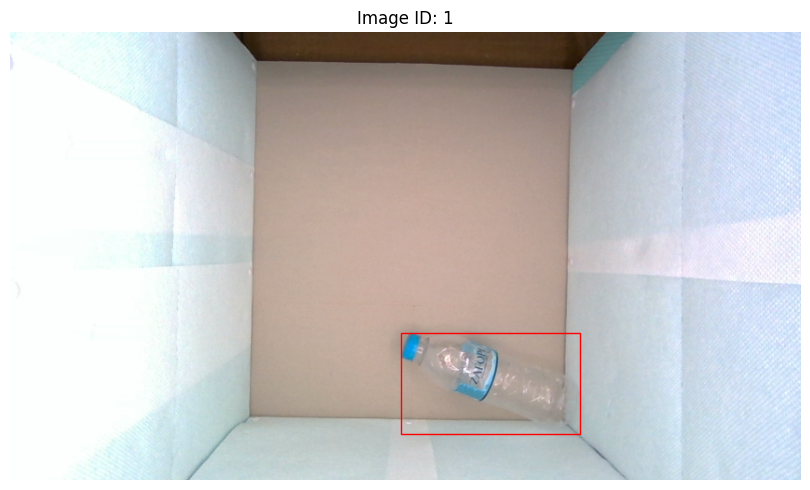

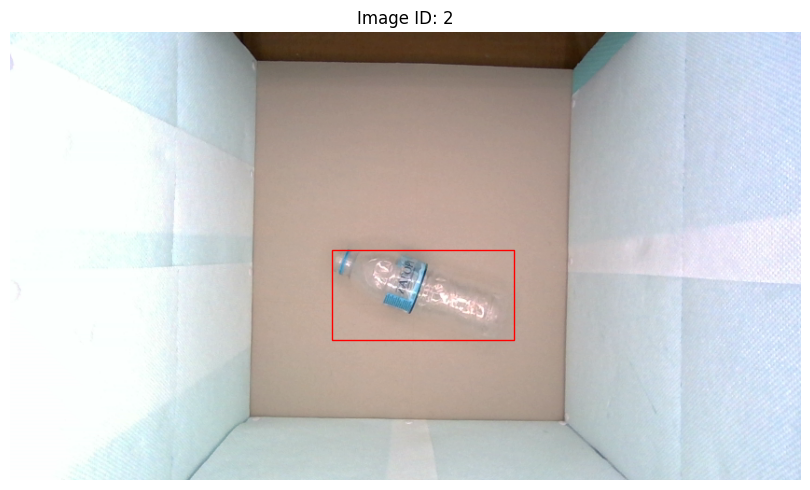

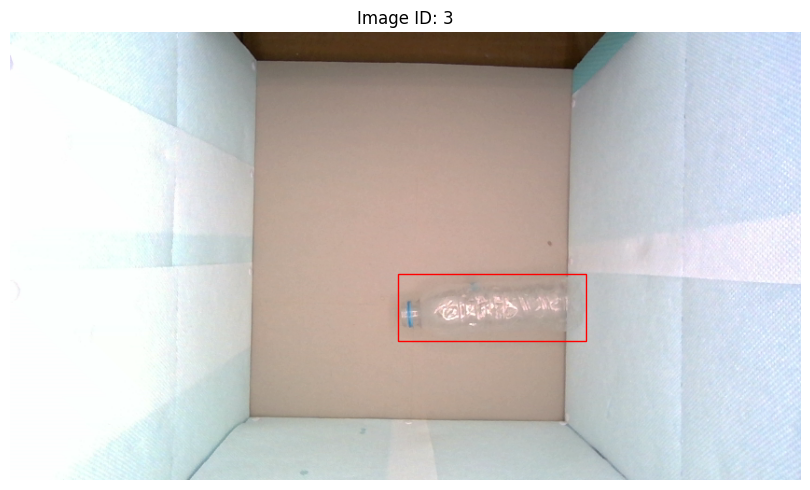

In [20]:
for image_id in images_df["id"].head(3):
    show_bbox(image_id)

На рассмотренных изображениях bounding boxes корректно охватывают размеченные предметы. Объекты располагаются внутри съёмочной установки, на фоне которой видны стенки и дно коробки. Положение и размер предметов в кадре могут различаться.

Использование одной съёмочной установки обеспечивает относительно однородные условия получения изображений, однако может ограничивать разнообразие фонов и ракурсов. Это следует учитывать при дальнейшем исследовании устойчивости модели к изменению условий съёмки.

### Оценим размер предметов на фотографиях

In [21]:
bbox_df = annotations_df[["image_id", "bbox"]].copy()

bbox_df[["x", "y", "width", "height"]] = pd.DataFrame(
    bbox_df["bbox"].tolist(),
    index=bbox_df.index
)

bbox_df["bbox_area"] = bbox_df["width"] * bbox_df["height"]

bbox_df.head()

,image_id,bbox,x,y,width,height,bbox_area
0,1,"[419, 322, 192, 108]",419,322,192,108,20736
1,2,"[345, 233, 195, 96]",345,233,195,96,18720
2,3,"[416, 259, 201, 71]",416,259,201,71,14271
3,4,"[342, 122, 178, 152]",342,122,178,152,27056
4,5,"[391, 154, 194, 66]",391,154,194,66,12804


In [22]:
bbox_df = bbox_df.merge(
    images_df[["id", "width", "height"]],
    left_on="image_id",
    right_on="id",
    how="left",
    suffixes=("_bbox", "_image"),
    validate="many_to_one"
)

bbox_df["relative_area"] = (
    bbox_df["bbox_area"]
    / (bbox_df["width_image"] * bbox_df["height_image"])
)

bbox_df["relative_area_pct"] = bbox_df["relative_area"] * 100

bbox_df.head()

,image_id,bbox,x,y,width_bbox,height_bbox,bbox_area,id,width_image,height_image,relative_area,relative_area_pct
0,1,"[419, 322, 192, 108]",419,322,192,108,20736,1,848,480,0.050943,5.094340
1,2,"[345, 233, 195, 96]",345,233,195,96,18720,2,848,480,0.045991,4.599057
2,3,"[416, 259, 201, 71]",416,259,201,71,14271,3,848,480,0.035060,3.506044
3,4,"[342, 122, 178, 152]",342,122,178,152,27056,4,848,480,0.066470,6.647013
4,5,"[391, 154, 194, 66]",391,154,194,66,12804,5,848,480,0.031456,3.145637


In [23]:
bbox_df[
    ["width_bbox", "height_bbox", "bbox_area", "relative_area_pct"]
].describe().round(2)

,width_bbox,height_bbox,bbox_area,relative_area_pct
count,3300.00,3300.00,3300.00,3300.00
mean,141.04,170.87,25721.97,6.32
std,63.28,77.28,20209.61,4.97
min,27.00,24.00,648.00,0.16
25%,96.00,108.00,12642.00,3.11
50%,130.00,160.00,20672.00,5.08
75%,173.25,222.00,32505.00,7.99
max,583.00,481.00,274593.00,67.46


Построим график

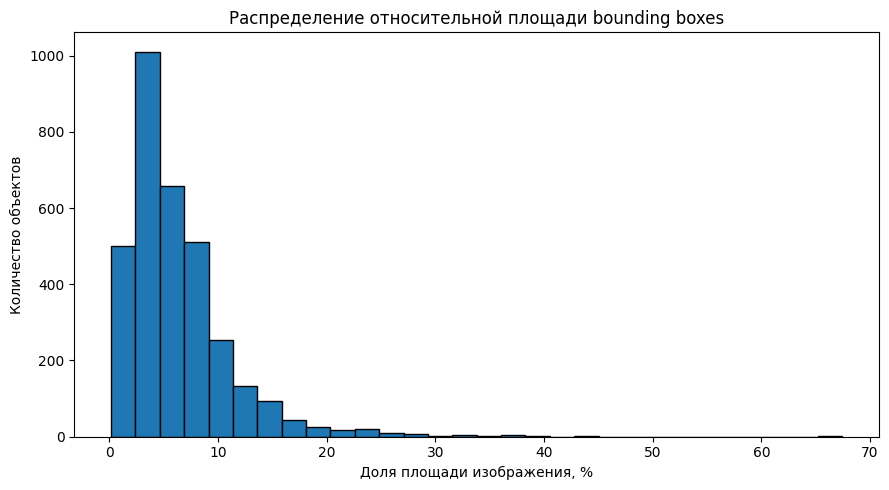

In [24]:
plt.figure(figsize=(9, 5))

plt.hist(
    bbox_df["relative_area_pct"],
    bins=30,
    edgecolor="black"
)

plt.title("Распределение относительной площади bounding boxes")
plt.xlabel("Доля площади изображения, %")
plt.ylabel("Количество объектов")

plt.tight_layout()
plt.show()

Можем сделать вывод, что большинство предметов небольшие, но иногда встречаются довольно крупные, занимающих вплоть до 67% изображения

Посмотрим, существуют ли некорректные рамки

In [25]:
invalid_bbox = (
    (bbox_df["width_bbox"] <= 0) |
    (bbox_df["height_bbox"] <= 0) |
    (bbox_df["x"] < 0) |
    (bbox_df["y"] < 0) |
    (bbox_df["x"] + bbox_df["width_bbox"] > bbox_df["width_image"]) |
    (bbox_df["y"] + bbox_df["height_bbox"] > bbox_df["height_image"])
)

print("Количество некорректных bounding boxes:", invalid_bbox.sum())

Количество некорректных bounding boxes: 19


Получили малое количество некорректных рамок - 19. Проверим, что именно с ними не так

In [26]:
invalid_details = bbox_df.loc[invalid_bbox].copy()
invalid_details["right"] = (
    invalid_details["x"] + invalid_details["width_bbox"]
)
invalid_details["bottom"] = (
    invalid_details["y"] + invalid_details["height_bbox"]
)
invalid_details[
    [
        "image_id", "x", "y",
        "width_bbox", "height_bbox",
        "right", "bottom",
        "width_image", "height_image"
    ]
]

print("Рамок с неположительной шириной:",(bbox_df["width_bbox"] <= 0).sum())
print("Рамок с неположительной высотой:", (bbox_df["height_bbox"] <= 0).sum())
print("Рамок с отрицательными координатами:",((bbox_df["x"] < 0) | (bbox_df["y"] < 0)).sum())
print("Рамок, выходящих за правую границу:",
      ((bbox_df["x"] + bbox_df["width_bbox"]) > bbox_df["width_image"]).sum())
print("Рамок, выходящих за нижнюю границу:",
      ((bbox_df["y"] + bbox_df["height_bbox"]) > bbox_df["height_image"]).sum())

Рамок с неположительной шириной: 0
Рамок с неположительной высотой: 0
Рамок с отрицательными координатами: 0
Рамок, выходящих за правую границу: 0
Рамок, выходящих за нижнюю границу: 19


Посмотрим, насколько превышение размера рамки за пределы изображения

In [27]:
invalid_details["overflow_bottom"] = ( invalid_details["bottom"] - invalid_details["height_image"] )

print("Минимальное превышение:",invalid_details["overflow_bottom"].min())
print("Максимальное превышение:",invalid_details["overflow_bottom"].max())
print("Среднее превышение:",round(invalid_details["overflow_bottom"].mean(), 2))

Минимальное превышение: 1
Максимальное превышение: 1
Среднее превышение: 1.0


Выявленные отклонения в один пиксель незначительны и предположительно связаны с особенностями вычисления координат. При подготовке данных к обучению их можно устранить ограничением координат рамок границами изображения.

## Визуальный анализ материалов на фото

In [28]:
images_meta = images_df.merge(
    df_eda[["ID", "Material"]],
    left_on="id",
    right_on="ID",
    how="left",
    validate="one_to_one"
)

examples = (
    images_meta.groupby("Material", group_keys=False)
    .sample(n=1, random_state=67)
    .sort_values("Material")
)

print("Количество выбранных изображений:", len(examples))

examples[["id", "file_name", "Material"]]

Количество выбранных изображений: 18


,id,file_name,Material
423,424,424ic_M41H99T0L0C0D1.png,ALU
3083,3084,3084ic_M72H41T1L1C0D0.png,Brown Glass (GL)
3268,3269,3269ic_M20H99T0L0C0D1.png,Cardboard (PAP)
3129,3130,3130ic_M70H00T1L1C0D0.png,Clear Glass (GL)
2725,2726,2726ic_M40H99T0L0C0D0.png,FE
3076,3077,3077ic_M71H20T1L1C0D0.png,Green Glass (GL)
59,60,60ic_M02H02T1L1C1D0.png,HDPE
2593,2594,2594ic_M04H01T0L0C0D0.png,LDPE
3203,3204,3204ic_M07H99T0L0C1D1.png,Other
37,38,38ic_M01H01T0L0C0D1.png,PET


### Посмотрим изображения

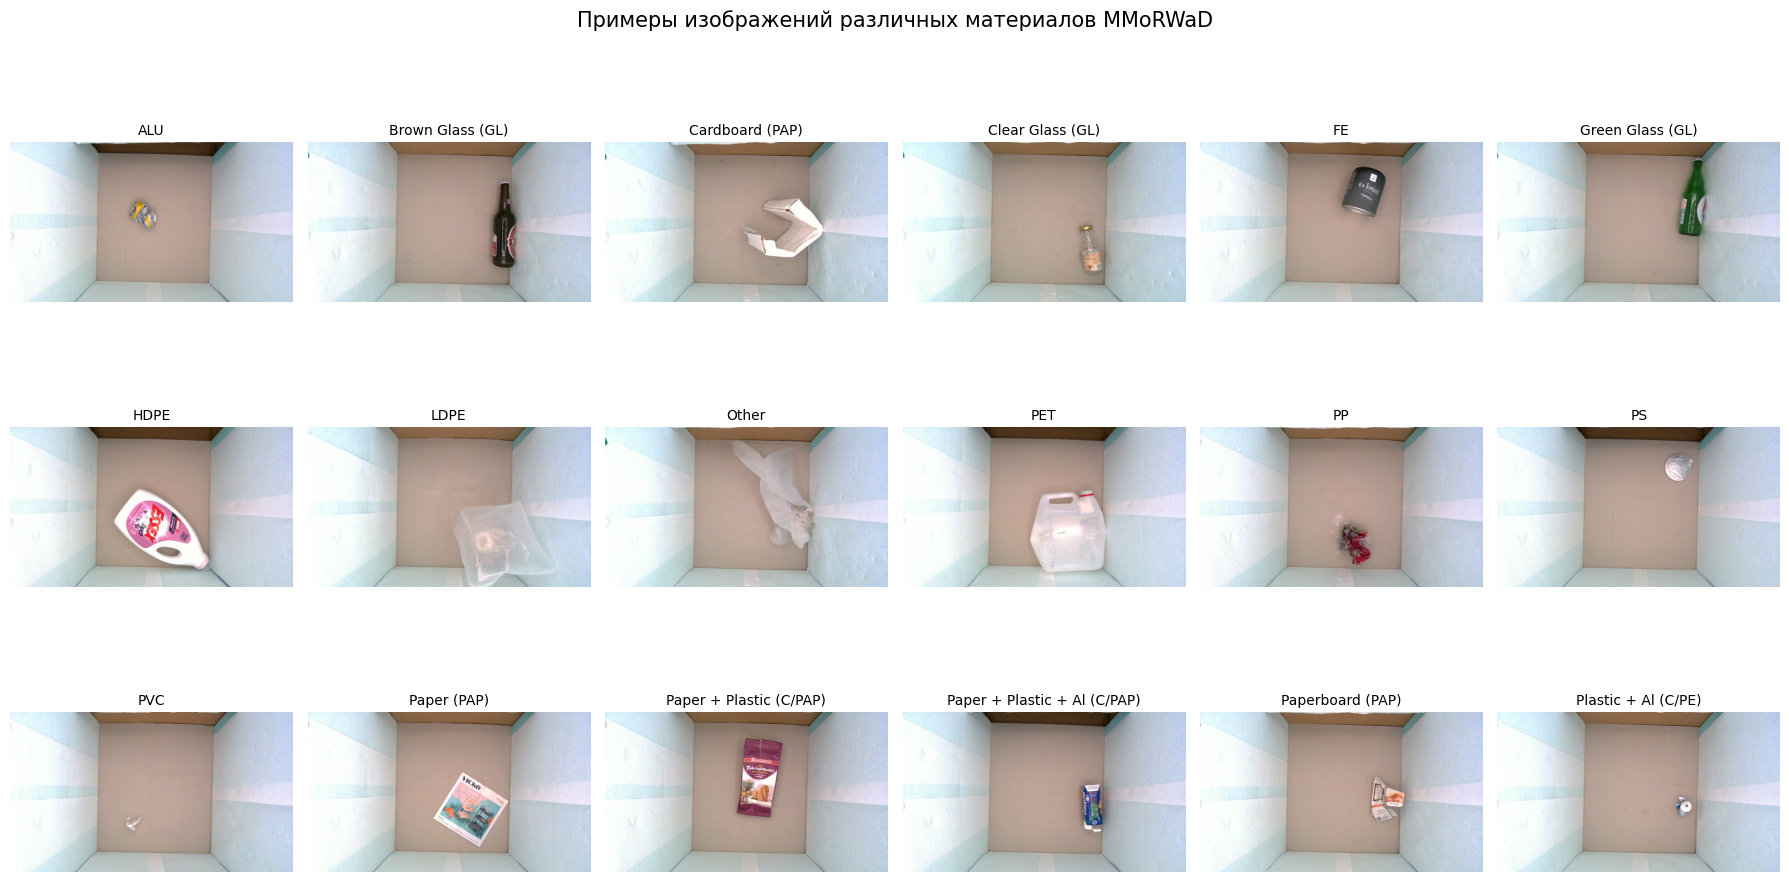

In [29]:
fig, axes = plt.subplots(3, 6, figsize=(18, 10))

for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    image = load_image(row["file_name"])

    ax.imshow(image)
    ax.set_title(row["Material"], fontsize=10)
    ax.axis("off")

plt.suptitle(
    "Примеры изображений различных материалов MMoRWaD",
    fontsize=15
)

plt.tight_layout()
plt.show()

На представленных примерах заметны различия в форме, цвете, размере и текстуре предметов разных материалов. При этом некоторые классы, особенно отдельные виды пластика и композитные материалы, сложно однозначно различить только по внешнему виду.

Объекты также значительно различаются по масштабу относительно изображения, что согласуется с результатами анализа bounding boxes.

### Посмотрим как выглядят объекты с загрязнениями

In [30]:
images_meta = images_df.merge(
    df_eda[["ID", "Material", "Hue", "Contaminates"]],
    left_on="id",
    right_on="ID",
    how="left",
    validate="one_to_one"
)

contaminated = images_meta[
    images_meta["Contaminates"] == "Yes"
]

print("Количество изображений с загрязнениями:", len(contaminated))

examples = contaminated.sample(
    n=min(12, len(contaminated)),
    random_state=67
)

examples[["id", "file_name", "Material", "Hue", "Contaminates"]]

Количество изображений с загрязнениями: 843


,id,file_name,Material,Hue,Contaminates
271,272,272ic_M01H31T1L0C1D0.png,PET,Light Blue,Yes
1392,1393,1393ic_M21H99T0L0C1D0.png,Paperboard (PAP),Other,Yes
1283,1284,1284ic_M07H99T0L0C1D0.png,Other,Other,Yes
1385,1386,1386ic_M21H99T0L0C1D1.png,Paperboard (PAP),Other,Yes
995,996,996ic_M05H99T0L0C1D0.png,PP,Other,Yes
2179,2180,2180ic_M01H00T1L1C1D0.png,PET,Clear,Yes
747,748,748ic_M01H00T1L1C1D1.png,PET,Clear,Yes
1044,1045,1045ic_M01H00T1L1C1D1.png,PET,Clear,Yes
1403,1404,1404ic_M21H99T0L0C1D1.png,Paperboard (PAP),Other,Yes
1411,1412,1412ic_M21H99T0L0C1D1.png,Paperboard (PAP),Other,Yes


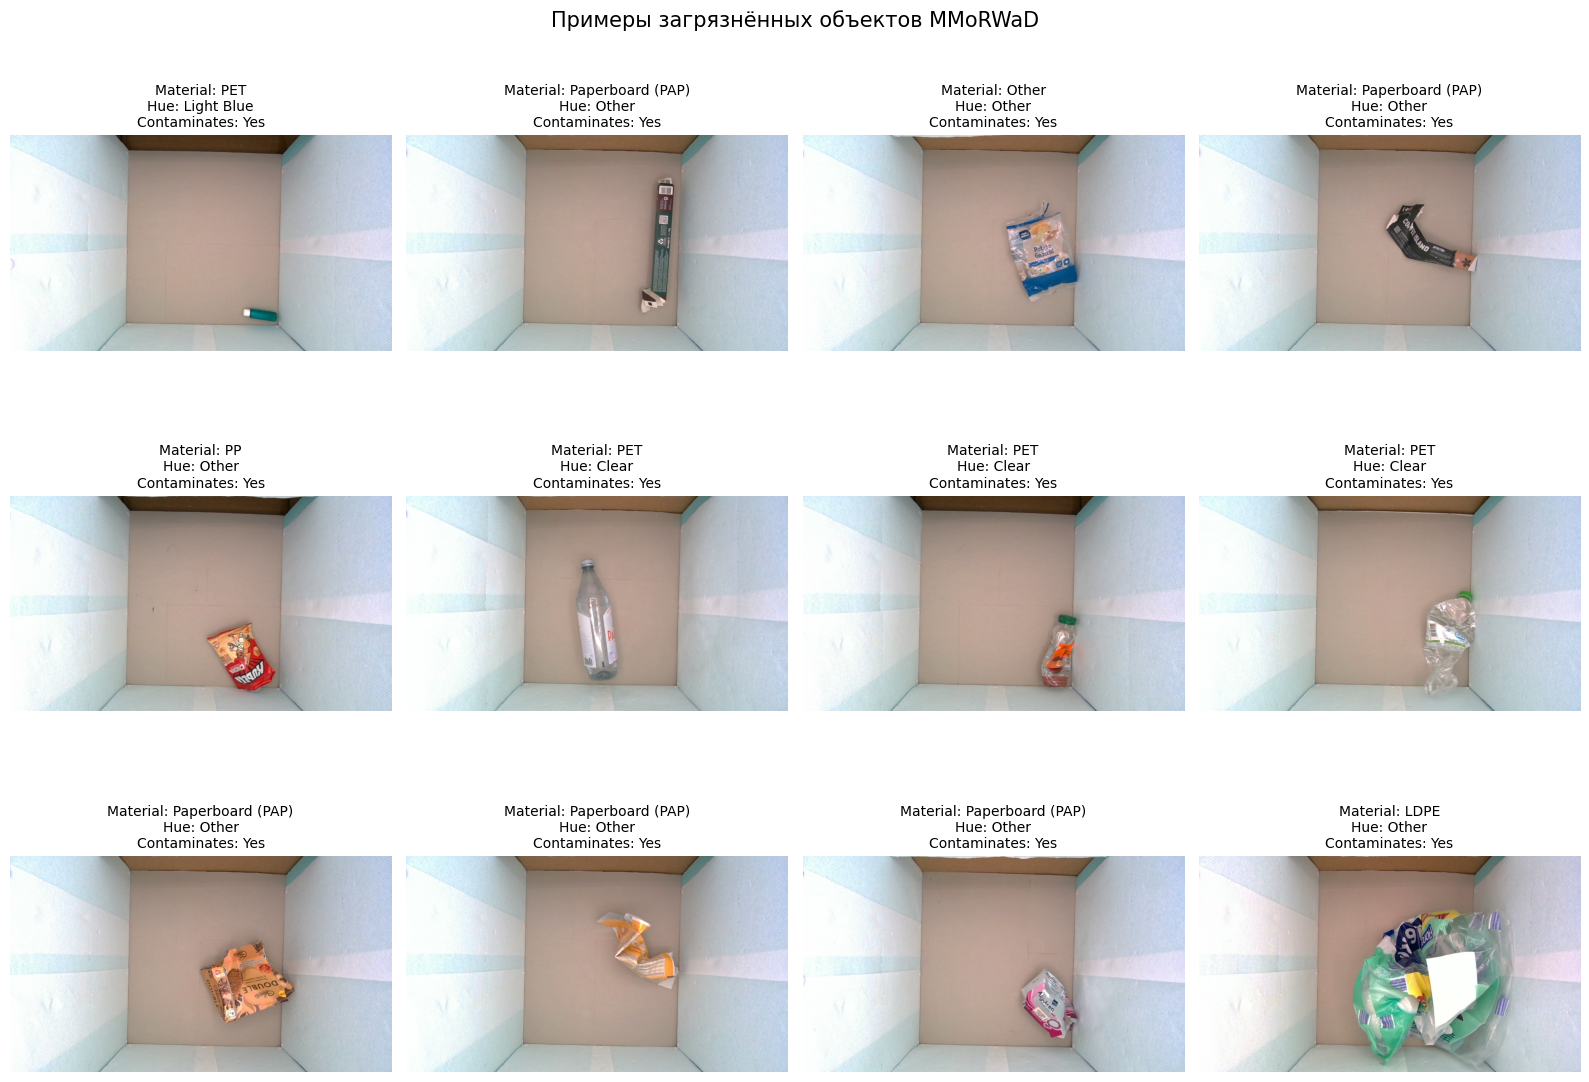

In [31]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    image = load_image(row["file_name"])

    ax.imshow(image)
    ax.set_title(
        f"Material: {row['Material']}\n"
        f"Hue: {row['Hue']}\n"
        f"Contaminates: {row['Contaminates']}",
        fontsize=10
    )
    ax.axis("off")

plt.suptitle(
    "Примеры загрязнённых объектов MMoRWaD",
    fontsize=15
)

plt.tight_layout()
plt.show()

## Исследование разделения данных

In [32]:
sample_path = download_from_zenodo(record, "sample_splits.csv")
object_path = download_from_zenodo(record, "object_splits.csv")

sample_splits = pd.read_csv(sample_path)
object_splits = pd.read_csv(object_path)

print("Разделение образцов:")
print("Размерность:", sample_splits.shape)
display(sample_splits.head())

print("\nРазделение физических предметов:")
print("Размерность:", object_splits.shape)
display(object_splits.head())

Файл скачан: /content/mmorwad_data/sample_splits.csv
Файл скачан: /content/mmorwad_data/object_splits.csv
Разделение образцов:
Размерность: (3300, 3)


,ID,item_name,split
0,1,zagori water bottle 0.5l,train
1,2,zagori water bottle 0.5l,train
2,3,zagori water bottle 0.5l,train
3,4,zagori water bottle 0.5l,train
4,5,zagori water bottle 0.5l,train



Разделение физических предметов:
Размерность: (721, 6)


,item_name,brand,split,primary_material,broad_category,n_samples
0,4all cup holder,4all,train,Paperboard (PAP),Paper,2
1,Sprite 0.5l,sprite,train,Polyethylene Terephthalate (PET),Plastic,14
2,Sprite cap 0.5l,sprite,train,High Density Polyethylene (HDPE),Plastic,1
3,a3 multiple papers,a3,train,Paper (PAP),Paper,1
4,a3 paper,a3,train,Paper (PAP),Paper,1


In [33]:
print("Количество образцов по выборкам:")
print(sample_splits["split"].value_counts())

print("\nКоличество физических предметов по выборкам:")
print(object_splits["split"].value_counts())

print("\nПропуски в sample_splits:")
print(sample_splits.isna().sum())

print("\nПропуски в object_splits:")
print(object_splits.isna().sum())

Количество образцов по выборкам:
split
train    2583
test      360
val       357
Name: count, dtype: int64

Количество физических предметов по выборкам:
split
train    570
test      76
val       75
Name: count, dtype: int64

Пропуски в sample_splits:
ID           0
item_name    0
split        0
dtype: int64

Пропуски в object_splits:
item_name           0
brand               0
split               0
primary_material    0
broad_category      0
n_samples           0
dtype: int64


Проверим пересечения физических предметов в разных выборках

In [34]:
item_splits = sample_splits.groupby("item_name")["split"].nunique()

print("Предметов, встречающихся в нескольких выборках:", (item_splits > 1).sum())

brand_splits = object_splits.groupby("brand")["split"].nunique()
print("Брендов, встречающихся в нескольких выборках:",(brand_splits > 1).sum())

Предметов, встречающихся в нескольких выборках: 0
Брендов, встречающихся в нескольких выборках: 0


проверим, что sample_splits.csv и object_splits.csv одинаково определяют принадлежность предмета к выборке.

In [35]:
split_check = sample_splits.merge(
    object_splits[["item_name", "split"]],
    on="item_name",
    how="left",
    suffixes=("_sample", "_object"),
    validate="many_to_one"
)

print("Не найдено соответствующих предметов:", split_check["split_object"].isna().sum())

print("Несовпадений выборок:", (split_check["split_sample"] != split_check["split_object"]).sum())

Не найдено соответствующих предметов: 0
Несовпадений выборок: 0


Разделение датасета на обучающую, валидационную и тестовую выборки выполнено приблизительно в пропорции 80/10/10. Проверка показала отсутствие пересечений названий предметов и брендов между выборками, что снижает риск утечки данных при обучении и оценке модели.

Также подтверждена согласованность файлов `sample_splits.csv` и `object_splits.csv`: для всех 3300 образцов найдены соответствующие предметы, а назначенные выборки полностью совпадают. Пропущенных значений в обоих файлах не обнаружено.

### Посмотрим распределение материалов между выборками

In [36]:
split_materials = df_eda[["ID", "Material"]].merge(
    sample_splits[["ID", "split"]],
    on="ID",
    how="left",
    validate="one_to_one"
)

assert split_materials["split"].notna().all()

material_split_counts = pd.crosstab(
    split_materials["Material"],
    split_materials["split"]
)

material_split_counts

split,test,train,val
Material,,,
ALU,16,135,16
Brown Glass (GL),3,30,3
Cardboard (PAP),11,39,11
Clear Glass (GL),14,85,10
FE,6,62,9
Green Glass (GL),4,0,6
HDPE,59,384,45
LDPE,9,25,1
Other,13,73,17


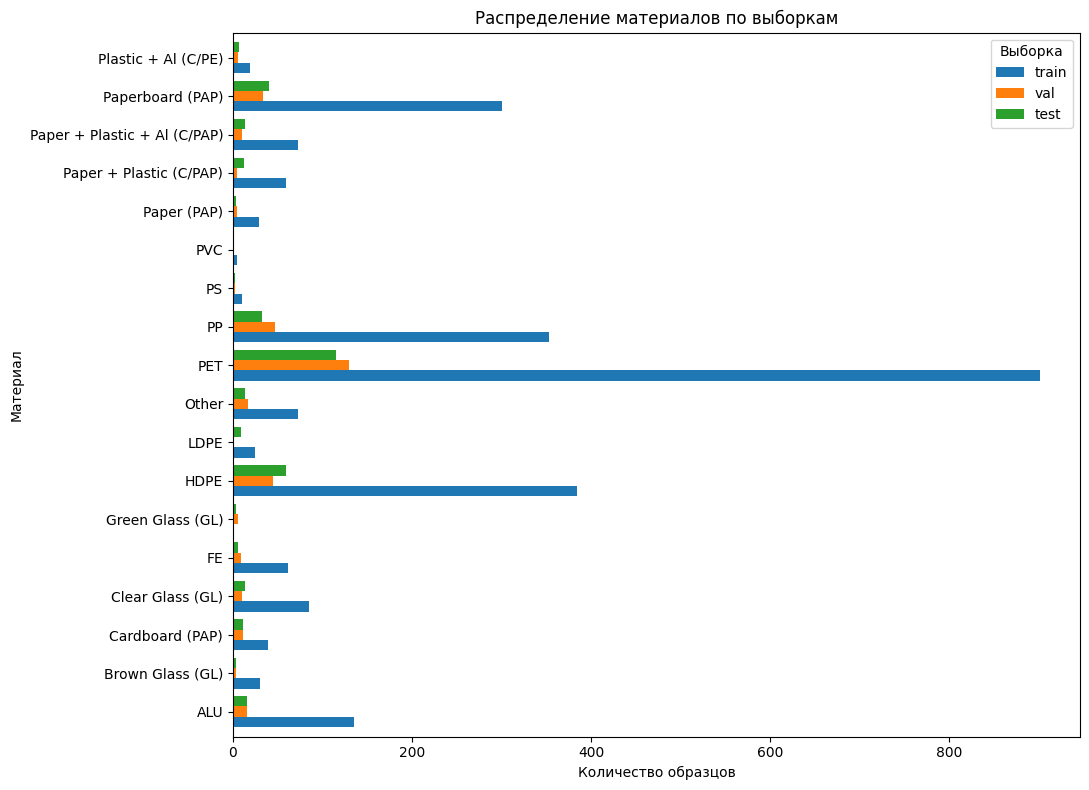

In [37]:
material_split_counts = material_split_counts.reindex(
    columns=["train", "val", "test"]
)

ax = material_split_counts.plot(
    kind="barh",
    figsize=(11, 8),
    width=0.8
)

ax.set_title("Распределение материалов по выборкам")
ax.set_xlabel("Количество образцов")
ax.set_ylabel("Материал")
ax.legend(title="Выборка")

plt.tight_layout()
plt.show()

Можем заметить, что в train нет зеленого стекла, что затруднит определение материала моделью.

С PVC наоборот, 0 объектов в test и validation, поэтому оценить качество его распознавания нельзя

В выборках сохраняется дисбаланс классов. Могут возникнуть проблемы с опредлением редких классов

## Итоговые выводы и ограничения датасета

### Основные результаты EDA

В ходе разведочного анализа была изучена структура датасета MMoRWaD, состав данных, распределение материалов и дополнительных характеристик, а также особенности изображений и детекционных аннотаций.

Датасет содержит 3300 образцов от 721 уникального предмета, относящихся к 18 классам материалов. Пропущенных значений и полных дубликатов в основной таблице не обнаружено. Также подтверждена согласованность информации о материалах между `dataset.csv` и `coco_annotations.json`.

Установлено, что распределение материалов сильно несбалансированно: 67,4% образцов относятся к пластиковой упаковке. Наиболее распространёнными материалами являются PET, HDPE и PP, тогда как некоторые классы представлены единичными образцами.

Анализ детекционных аннотаций показал, что каждому изображению соответствует один размеченный объект. Медианная площадь bounding box составляет 5,08% площади изображения, то есть многие предметы занимают относительно небольшую часть кадра. При проверке геометрической корректности выявлено 19 рамок (0,58%), выходящих за нижнюю границу изображения ровно на один пиксель.

Официальное разделение данных выполнено приблизительно в пропорции 80/10/10. Пересечений названий предметов и брендов между выборками не обнаружено.

### Выявленные ограничения и допущения

По результатам анализа можно выделить следующие ограничения исходного датасета:

1. **Дисбаланс классов.** Значительное преобладание отдельных пластиков и небольшое количество примеров редких материалов могут осложнять их распознавание.

2. **Неполная представленность классов в выборках.** Зелёное стекло полностью отсутствует в обучающей выборке, а PVC — в валидационной и тестовой, что ограничивает возможности обучения и объективной оценки качества для данных классов.

3. **Однородные условия съёмки.** Изображения получены с использованием одной экспериментальной установки, с похожими фоном и освещением. Это потенциально ограничивает способность модели работать в других условиях.

4. **Один объект на изображении.** В исходных данных отсутствуют аннотации сцен с несколькими одновременно расположенными предметами, поэтому работа модели в таких условиях требует дополнительного исследования.

5. **Визуальная неоднозначность материалов.** Некоторые виды пластика и композитных упаковок трудно однозначно различить по внешнему виду, что может осложнять классификацию материала обнаруженного объекта.

В рамках анализа предполагается, что предоставленные авторами обозначения материалов и дополнительных признаков корректны. Проверка соответствия реального состава предметов указанным материалам не проводилась.

### Выводы для дальнейшего обогащения

Полученные результаты позволяют определить основные направления дальнейшего обогащения датасета.

Для ручного обогащения уже проведена собственная фотосъёмка бытовых предметов из различных материалов. Получено около 130 исходных фотографий, из которых после проверки качества и соответствия классам MMoRWaD будут отобраны подходящие изображения.

Съёмка выполнялась с использованием отдельной картонной установки размером 38 × 45 × 30 см, с камерой, направленной сверху. В отличие от оригинального датасета, фотографии получены с другого расстояния и на более светлом фоне. Это позволит дополнить набор примерами, сделанными в отличающихся условиях, и в дальнейшем проверить влияние такого обогащения на качество детекции.
